In [1]:
import sys
import numpy as np
import pandas as pd
import joblib
import shap

sys.path.insert(0, '..')              # notebooks/ -> repo root, so src is importable
from src.columns import NON_FEATURES

print("shap", shap.__version__)


# ---- 1. load ------------------------------------------------------------
train = pd.read_parquet('../data/processed/features_train.parquet')
test  = pd.read_parquet('../data/processed/features_test.parquet')

assert train['issue_d'].is_monotonic_increasing, "train is not in time order"
assert test['issue_d'].is_monotonic_increasing,  "test is not in time order"


# ---- 2. the same split as slices 5 and 6, by date not by row position ---
SPLIT_DATE  = pd.Timestamp('2016-01-01')
train_inner = train[train['issue_d'] <  SPLIT_DATE].copy()
valid       = train[train['issue_d'] >= SPLIT_DATE].copy()


# ---- 3. prove the ground is identical to the earlier slices -------------
expected = [("train_inner", train_inner, 16134, 0.1890),
            ("valid",       valid,        4768, 0.2391),
            ("test",        test,         5378, 0.2365)]

for name, df, n_rows, bad_rate in expected:
    assert len(df) == n_rows, f"{name} has {len(df)} rows, earlier slices had {n_rows}"
    assert abs(df['target'].mean() - bad_rate) < 1e-4, \
        f"{name} bad rate {df['target'].mean():.4f}, earlier slices had {bad_rate}"

print(pd.DataFrame([
    {"set": name, "rows": len(df),
     "from": df['issue_d'].min().date(), "to": df['issue_d'].max().date(),
     "bad_rate": df['target'].mean()}
    for name, df, _, _ in expected
]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))


# ---- 4. X and y ---------------------------------------------------------
X_train_inner = train_inner.drop(columns=NON_FEATURES)
y_train_inner = train_inner['target']

X_test = test.drop(columns=NON_FEATURES)
y_test = test['target']

assert X_train_inner.shape[1] == 71, f"expected 71 features, got {X_train_inner.shape[1]}"
assert list(X_train_inner.columns) == list(X_test.columns), "test columns differ"


# ---- 5. the shipped bundle, and slice 6's published probabilities -------
bundle    = joblib.load('../models/calibrated_logreg.joblib')
published = pd.read_parquet('../data/processed/predictions_test_slice6.parquet')

# the scaler works by POSITION, so the order has to be the bundle's order
assert list(X_test.columns) == bundle['columns'], \
    "feature order does not match the bundle - the scaler would be applied to the wrong columns"

# row order first, as always
assert np.array_equal(published['target'].values, y_test.values), \
    "the published predictions are not in the same row order as test"

print(f"\nbundle: C={bundle['C']}  "
      f"{bundle['n_features_used']} of {len(bundle['columns'])} features used")
print(f"        {bundle['calibration']}")

c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


shap 0.54.1
        set  rows       from         to  bad_rate
train_inner 16134 2013-01-01 2015-12-01    0.1890
      valid  4768 2016-01-01 2016-08-01    0.2391
       test  5378 2016-09-01 2017-12-01    0.2365

bundle: C=0.05  47 of 71 features used
        sigmoid (Platt), fitted on validation log-odds


In [3]:
# ---- 1. scale both halves with the bundle's own scaler ------------------
scaler = bundle['scaler']
model  = bundle['model']
cols   = bundle['columns']

Xtr_s = pd.DataFrame(scaler.transform(X_train_inner[cols]),   # the background
                     columns=cols, index=X_train_inner.index)
Xte_s = pd.DataFrame(scaler.transform(X_test[cols]),          # what we explain
                     columns=cols, index=X_test.index)


# ---- 2. the reference point must be zero --------------------------------
# SHAP measures "compared to a typical borrower". That typical borrower is
# the mean of the background. The scaler was FITTED on these rows, so their
# scaled mean is exactly zero - which is why the formula below collapses to
# a single multiply. If this fails, the scaler is not the one fitted here.
ref = Xtr_s.values.mean(axis=0)
print(f"background mean, largest absolute value: {np.abs(ref).max():.2e}")
assert np.abs(ref).max() < 1e-10, "the background mean is not zero"


# ---- 3. the contributions, by hand --------------------------------------
coef = model.coef_[0]          # (71,)
base = model.intercept_[0]     # the base value: one number

phi = coef * Xte_s.values      # broadcasting: (71,) * (5378, 71) -> (5378, 71)

print(f"contributions: {phi.shape}   base value: {base:+.4f}")


# ---- 4. prove it adds up ------------------------------------------------
# for a LINEAR model this is exact arithmetic, not an estimate. assert it.
score = model.decision_function(Xte_s)
recon = phi.sum(axis=1) + base

print(f"max |contributions + base  -  decision_function| = "
      f"{np.abs(recon - score).max():.2e}")
assert np.allclose(recon, score, atol=1e-10), "the contributions do not add up"


# ---- 5. shap's own explainer, same model, same background ---------------
# shap's default masker subsamples the background to 100 rows, which moves
# the reference point. Build the masker ourselves so it uses all 16,134.
masker    = shap.maskers.Independent(Xtr_s, max_samples=len(Xtr_s))
explainer = shap.LinearExplainer(model, masker)
phi_shap  = np.asarray(explainer.shap_values(Xte_s))

print(f"\nshap values:    {phi_shap.shape}")
print(f"shap base:      {np.ravel(explainer.expected_value)[0]:+.4f}   "
      f"(model intercept {base:+.4f})")
print(f"max difference: {np.abs(phi - phi_shap).max():.2e}")

assert np.allclose(phi, phi_shap, atol=1e-8), "shap disagrees with the hand formula"
assert np.isclose(np.ravel(explainer.expected_value)[0], base, atol=1e-8), \
    "shap's base value is not the intercept"

assert np.allclose(phi, phi_shap, atol=1e-8), "shap disagrees with the hand formula"
assert np.isclose(np.ravel(explainer.expected_value)[0], base, atol=1e-8), \
    "shap's base value is not the intercept"


# ---- 6. the 24 features L1 killed ---------------------------------------
dead = (coef == 0)
print(f"\nfeatures with a zero coefficient: {dead.sum()} of {len(coef)}")
assert dead.sum() == len(cols) - bundle['n_features_used'], "dead count disagrees with the bundle"
assert (phi[:, dead] == 0).all(), "a dead feature contributed something"
print("every one of them contributes exactly zero on every row, as it must")


# ---- 7. collect, with the probability alongside -------------------------
meta = pd.DataFrame({
    'issue_d':  test['issue_d'].values,
    'target':   y_test.values,
    'score':    score,                          # log-odds: base + row sum, exact
    'p_logreg': published['p_logreg'].values,   # READOUT only - not part of the sum
})

shap_df = pd.concat([meta, pd.DataFrame(phi, columns=cols)], axis=1)
shap_df.to_parquet('../data/processed/shap_logreg_test.parquet', index=False)

print(f"\nsaved: shap_logreg_test.parquet {shap_df.shape}")

# calibration is linear in the score, so contributions in CALIBRATED log-odds
# are just these multiplied by the Platt slope. recorded, not applied.
print(f"Platt slope {bundle['calibrator'].coef_[0][0]:+.4f}  "
      f"shift {bundle['calibrator'].intercept_[0]:+.4f}")


# ---- 8. what the per-row view buys you ----------------------------------
# slice 5's row 3240: probability 1.000000 on a loan that was repaid
ROW = 3240
assert shap_df.loc[ROW, 'p_logreg'] > 0.999, "row 3240 is not the extreme row"

row = shap_df.loc[ROW, cols].astype(float).sort_values(key=np.abs, ascending=False)

print(f"\n--- row {ROW}, repaid, scored {shap_df.loc[ROW, 'score']:+.3f} ---")
print(row.head(5).to_string(float_format=lambda v: f"{v:+.3f}"))
print(f"...plus {len(cols) - 5} others and a base of {base:+.3f}")

# the same borrower with that one feature removed
print(f"\nscore without loan_to_income: "
      f"{shap_df.loc[ROW, 'score'] - row['loan_to_income']:+.3f}")

background mean, largest absolute value: 9.78e-16
contributions: (5378, 71)   base value: -1.6291
max |contributions + base  -  decision_function| = 2.13e-14

shap values:    (5378, 71)
shap base:      -1.6291   (model intercept -1.6291)
max difference: 2.22e-16

features with a zero coefficient: 24 of 71
every one of them contributes exactly zero on every row, as it must

saved: shap_logreg_test.parquet (5378, 75)
Platt slope +0.9475  shift +0.2898

--- row 3240, repaid, scored +33.368 ---
loan_to_income               +34.508
term                          +0.727
application_type_Joint App    +0.284
fico                          -0.210
acc_open_past_24mths          -0.178
...plus 66 others and a base of -1.629

score without loan_to_income: -1.139


In [7]:
import time

# ---- 1. the slice 6 bundle ---------------------------------------------
bundle_lgb = joblib.load('../models/calibrated_lgbm.joblib')
model_lgb  = bundle_lgb['model']

assert bundle_lgb['columns'] == cols, "the two bundles disagree about column order"
print("params:", bundle_lgb['params']['num_leaves'], "leaves,",
      bundle_lgb['params']['n_estimators'], "trees")


# ---- 2. the background, chosen on purpose and written down -------------
# step 1's lesson: a documented small reference beats an undocumented one
BG_ROWS, BG_SEED = 1000, 42

rng        = np.random.default_rng(BG_SEED)
bg_idx     = np.sort(rng.choice(len(X_train_inner), size=BG_ROWS, replace=False))
background = X_train_inner.iloc[bg_idx]

print(f"background: {len(background)} of {len(X_train_inner)} train_inner rows, seed {BG_SEED}")


# ---- 3. helpers: shap's output shape varies between versions -----------
def as_matrix(sv):
    """Keep the positive class, whatever shape this version returns."""
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:                       # (rows, features, classes)
        sv = sv[:, :, 1]
    return sv


def as_scalar(v):
    v = np.ravel(v)
    return float(v[1] if v.size == 2 else v[0])


def raw_margin(m, X):
    """Same guard as src/predict.py - the shape differs between versions."""
    r = np.asarray(m.predict_proba(X, raw_score=True))
    return r[:, 1] if r.ndim == 2 else r


# ---- 4. build the masker ourselves, and check it obeyed ----------------
# shap wraps a raw background in a masker capped at 100 rows and says
# nothing useful about it. Forcing it is half the job; asserting that the
# forcing worked is the other half.
masker = shap.maskers.Independent(background, max_samples=len(background))

explainer_lgb = shap.TreeExplainer(model_lgb, data=masker,
                                   feature_perturbation='interventional')

kept = np.asarray(explainer_lgb.data).shape[0]
print(f"shap kept {kept} of the {len(background)} background rows")
assert kept == len(background), "shap still subsampled the background"


# ---- 5. time it on 100 rows before running all 5,378 -------------------
t0 = time.perf_counter()
_  = explainer_lgb.shap_values(X_test[cols].iloc[:100])
per_100 = time.perf_counter() - t0

print(f"\n100 rows took {per_100:.1f}s  ->  all 5,378 will take about "
      f"{per_100 * len(X_test) / 100 / 60:.1f} min")


# ---- 6. all of it ------------------------------------------------------
t0       = time.perf_counter()
phi_lgb  = as_matrix(explainer_lgb.shap_values(X_test[cols]))
base_lgb = as_scalar(explainer_lgb.expected_value)

print(f"done in {(time.perf_counter() - t0) / 60:.1f} min")
print(f"shap values: {phi_lgb.shape}   base value: {base_lgb:+.4f}")


# ---- 7. prove it adds up -----------------------------------------------
raw_test = raw_margin(model_lgb, X_test[cols])
recon    = phi_lgb.sum(axis=1) + base_lgb

print(f"\nmax |contributions + base  -  raw margin| = {np.abs(recon - raw_test).max():.2e}")
assert np.allclose(recon, raw_test, atol=1e-6), "the contributions do not add up"


# ---- 8. what the base value actually is --------------------------------
# for interventional TreeSHAP it is the mean raw margin over the BACKGROUND.
# that is an exact identity, so assert it - it is what caught the silent
# subsampling in the first place.
bg_mean = raw_margin(model_lgb, background).mean()
print(f"mean raw margin over the background: {bg_mean:+.4f}")
assert np.isclose(base_lgb, bg_mean, atol=1e-6), "base value is not the background mean"

# NOT the same as the log-odds of the base rate, and the gap is expected:
# the mean of log-odds is not the log-odds of the mean (Jensen). context only.
rate = y_train_inner.mean()
print(f"log-odds of the train_inner bad rate ({rate:.4f}): "
      f"{np.log(rate / (1 - rate)):+.4f}   <- different thing, not a check")


# ---- 9. collect and save -----------------------------------------------
meta_lgb = pd.DataFrame({
    'issue_d':      test['issue_d'].values,
    'target':       y_test.values,
    'raw_margin':   raw_test,                          # base + row sum, exact
    'p_lgbm_tuned': published['p_lgbm_tuned'].values,  # READOUT only - not additive
})

shap_lgb_df = pd.concat([meta_lgb, pd.DataFrame(phi_lgb, columns=cols)], axis=1)
shap_lgb_df.to_parquet('../data/processed/shap_lgbm_test.parquet', index=False)

print(f"\nsaved: shap_lgbm_test.parquet {shap_lgb_df.shape}")
print(f"RECORD IN THE DOC: interventional, background {BG_ROWS} rows of "
      f"train_inner, seed {BG_SEED}, base value {base_lgb:+.4f}")

params: 4 leaves, 239 trees
background: 1000 of 16134 train_inner rows, seed 42
shap kept 1000 of the 1000 background rows

100 rows took 0.9s  ->  all 5,378 will take about 0.8 min


100%|===================| 5373/5378 [00:48<00:00]        

done in 0.8 min
shap values: (5378, 71)   base value: -1.6084

max |contributions + base  -  raw margin| = 3.80e-08
mean raw margin over the background: -1.6084
log-odds of the train_inner bad rate (0.1890): -1.4562   <- different thing, not a check

saved: shap_lgbm_test.parquet (5378, 75)
RECORD IN THE DOC: interventional, background 1000 rows of train_inner, seed 42, base value -1.6084


In [5]:
# ---- what IS shap's base value the mean of? ----------------------------
print(f"shap base value : {base_lgb:+.8f}")
print(f"my bg_mean      : {bg_mean:+.8f}")
print(f"difference      : {base_lgb - bg_mean:+.3e}\n")

for name, rows in [("background[:100]",      background.iloc[:100]),
                   ("background[:500]",      background.iloc[:500]),
                   ("background (all 1000)", background),
                   ("all train_inner",       X_train_inner)]:
    m = raw_margin(model_lgb, rows[cols]).mean()
    print(f"{name:24s} {m:+.8f}    diff {base_lgb - m:+.3e}")

# the decisive one: what did shap actually keep?
d = getattr(explainer_lgb, 'data', None)
print("\nexplainer.data rows :", None if d is None else np.asarray(d).shape)
print("feature_perturbation:", getattr(explainer_lgb, 'feature_perturbation', '?'))
print("model_output        :", getattr(explainer_lgb, 'model_output', '?'))

shap base value : -1.64931806
my bg_mean      : -1.60841800
difference      : -4.090e-02

background[:100]         -1.69224351    diff +4.293e-02
background[:500]         -1.61882545    diff -3.049e-02
background (all 1000)    -1.60841800    diff -4.090e-02
all train_inner          -1.56899567    diff -8.032e-02

explainer.data rows : (100, 71)
feature_perturbation: interventional
model_output        : raw


In [11]:
# ---- 1. one explainer, one supported mode -----------------------------
# shap only supports interactions in tree_path_dependent mode - the guard
# saying so is commented out in _tree.py:843, so the interventional call
# runs silently and produces something that reconciles with nothing.
# Interactions FIRST on a fresh explainer: _get_shap_interactions_output
# only sets expected_value if it is not already set, so calling
# shap_values first would leave the matrix with a base from elsewhere.
explainer_i = shap.TreeExplainer(model_lgb,
                                 feature_perturbation='tree_path_dependent')

X_in = X_test[cols]

inter = np.asarray(explainer_i.shap_interaction_values(X_in))
if inter.ndim == 4:                      # (rows, features, features, classes)
    inter = inter[:, :, :, 1]

phi_i  = as_matrix(explainer_i.shap_values(X_in))
base_i = as_scalar(explainer_i.expected_value)

print(f"interaction values: {inter.shape}   {inter.nbytes / 1e6:.0f} MB")
print(f"base value:         {base_i:+.6f}   "
      f"(interventional values use {base_lgb:+.6f} - different reference, on purpose)")


# ---- 2. the matrix must be symmetric ----------------------------------
print(f"\nmax |M - M.T| = {np.abs(inter - inter.transpose(0, 2, 1)).max():.2e}")
assert np.allclose(inter, inter.transpose(0, 2, 1), atol=1e-8), "not symmetric"


# ---- 3. the collapse identity, against THIS explainer's values --------
collapsed = inter.sum(axis=2)
print(f"max |collapsed  -  shap values| = {np.abs(collapsed - phi_i).max():.2e}")
assert np.allclose(collapsed, phi_i, atol=1e-5), "the collapse identity fails"


# ---- 4. and it must still reconstruct the prediction ------------------
err = np.abs(inter.sum(axis=(1, 2)) + base_i - raw_test).max()
print(f"max |all cells + base  -  raw margin| = {err:.2e}")
assert err < 1e-4, "the interaction matrix does not reconstruct the model output"


# ---- 5. split the diagonal from the rest ------------------------------
d    = np.arange(inter.shape[1])
main = np.diagonal(inter, axis1=1, axis2=2)    # (rows, 71) - acting alone
off  = inter.copy()
off[:, d, d] = 0.0                             # everything else: pairs

abs_main, abs_off = np.abs(main).sum(), np.abs(off).sum()
share = abs_off / (abs_main + abs_off)

print(f"\nabsolute main effects:  {abs_main:12,.1f}")
print(f"absolute interactions:  {abs_off:12,.1f}")
print(f"interaction share:      {share:.4f}   ({share:.2%} of all absolute effect)")


# ---- 6. the biggest pairs ---------------------------------------------
pair = pd.DataFrame(np.abs(off).sum(axis=0), index=cols, columns=cols)

pairs = (pair.where(np.triu(np.ones(pair.shape), k=1).astype(bool))
             .stack()
             .sort_values(ascending=False)
             .head(10))

print("\n--- strongest feature pairs, total absolute interaction ---")
print(pairs.to_string(float_format=lambda v: f"{v:,.1f}"))
print(f"\ntop pair is {pairs.iloc[0] / (abs_main + abs_off):.2%} of all absolute effect")

c:\data science and machine learning\projects\credit-risk-engine\.venv\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


interaction values: (5378, 71, 71)   217 MB
base value:         -1.568996   (interventional values use -1.608418 - different reference, on purpose)

max |M - M.T| = 1.12e-16
max |collapsed  -  shap values| = 9.99e-16
max |all cells + base  -  raw margin| = 5.77e-15

absolute main effects:       6,624.8
absolute interactions:       2,174.4
interaction share:      0.2471   (24.71% of all absolute effect)

--- strongest feature pairs, total absolute interaction ---
acc_open_past_24mths  loan_to_income         94.5
term                  avg_cur_bal            92.5
                      dti                    53.9
                      fico                   51.1
loan_to_income        fico                   47.8
term                  acc_open_past_24mths   35.7
acc_open_past_24mths  fico                   33.8
dti                   acc_open_past_24mths   32.2
acc_open_past_24mths  bc_open_to_buy         29.7
term                  tot_hi_cred_lim        27.5

top pair is 1.07% of all absolut

In [12]:
from sklearn.metrics import roc_auc_score
import gc

# ---- A. does the 24.71% actually move predictions? --------------------
main_row = main.sum(axis=1)          # every feature acting alone, per row
off_row  = off.sum(axis=(1, 2))      # net pairwise, signs allowed to cancel

# the three pieces must rebuild the margin
assert np.allclose(base_i + main_row + off_row, raw_test, atol=1e-6), \
    "the split does not reconstruct the model output"

print("--- per row, in log-odds ---")
print(f"main effects    : std {main_row.std():.4f}   mean abs {np.abs(main_row).mean():.4f}")
print(f"net interactions: std {off_row.std():.4f}   mean abs {np.abs(off_row).mean():.4f}")
print(f"ratio of spreads: {off_row.std() / main_row.std():.4f}")

# how much survives once signs are allowed to cancel?
abs_row = np.abs(off).sum(axis=(1, 2))
print(f"\nabsolute interaction mass per row : {abs_row.mean():.4f}")
print(f"net after cancelling              : {np.abs(off_row).mean():.4f}"
      f"   ({np.abs(off_row).mean() / abs_row.mean():.1%} survives)")


# ---- the direct test: delete every interaction, keep the ranking? -----
auc_full = roc_auc_score(y_test, raw_test)
auc_main = roc_auc_score(y_test, main_row)

print(f"\nAUC, full model        : {auc_full:.4f}")
print(f"AUC, main effects only : {auc_main:.4f}")
print(f"cost of deleting every interaction: {auc_full - auc_main:+.4f}")


# ---- B. the same share on train_inner, same number of rows -----------
# same n, so the comparison is not confounded by sample size
SAMPLE_SEED = 7
rng_t  = np.random.default_rng(SAMPLE_SEED)
idx_t  = np.sort(rng_t.choice(len(X_train_inner), size=len(X_test), replace=False))
X_tr_s = X_train_inner.iloc[idx_t][cols]

inter_tr = np.asarray(explainer_i.shap_interaction_values(X_tr_s))
if inter_tr.ndim == 4:
    inter_tr = inter_tr[:, :, :, 1]

d2      = np.arange(inter_tr.shape[1])
main_tr = np.diagonal(inter_tr, axis1=1, axis2=2)
off_tr  = inter_tr.copy()
off_tr[:, d2, d2] = 0.0

share_tr = np.abs(off_tr).sum() / (np.abs(main_tr).sum() + np.abs(off_tr).sum())

print(f"\n--- interaction share, {len(X_tr_s):,} rows each ---")
print(f"train_inner (seed {SAMPLE_SEED}): {share_tr:.2%}")
print(f"test                  : {share:.2%}")
print(f"difference            : {share_tr - share:+.2%}")

del inter_tr, off_tr, main_tr
gc.collect()

--- per row, in log-odds ---
main effects    : std 0.5820   mean abs 0.4665
net interactions: std 0.0929   mean abs 0.0731
ratio of spreads: 0.1596

absolute interaction mass per row : 0.4043
net after cancelling              : 0.0731   (18.1% survives)

AUC, full model        : 0.6726
AUC, main effects only : 0.6725
cost of deleting every interaction: +0.0001

--- interaction share, 5,378 rows each ---
train_inner (seed 7): 24.93%
test                  : 24.71%
difference            : +0.22%


73

In [13]:
from scipy.stats import spearmanr

# ---- 1. four importance measures, one row per feature -----------------
gain = pd.Series(model_lgb.booster_.feature_importance(importance_type='gain'),
                 index=model_lgb.booster_.feature_name())

imp = pd.DataFrame({
    'abs_coef':    np.abs(coef),                   # logistic: the weight
    'shap_logreg': np.abs(phi).mean(axis=0),       # logistic: average effect
    'shap_lgbm':   np.abs(phi_lgb).mean(axis=0),   # boosted:  average effect
    'lgbm_gain':   gain.reindex(cols).fillna(0).values,   # boosted: split gain
}, index=cols)


# ---- 2. why the first two differ at all --------------------------------
# mean|shap| = |coef| x mean|scaled value|. exact, so assert it.
expected = np.abs(coef) * np.abs(Xte_s.values).mean(axis=0)
print(f"max |mean abs shap  -  |coef| x mean abs scaled| = "
      f"{np.abs(imp['shap_logreg'].values - expected).max():.2e}")
assert np.allclose(imp['shap_logreg'].values, expected, atol=1e-12)
print("so the only thing separating them is how spread out each feature is")


# ---- 3. do the four agree on the ORDER? --------------------------------
rho = pd.DataFrame(
    [[spearmanr(imp[a], imp[b]).statistic for b in imp.columns] for a in imp.columns],
    index=imp.columns, columns=imp.columns)

print("\n--- rank correlation between the four measures ---")
print(rho.to_string(float_format=lambda v: f"{v:.3f}"))


# ---- 4. the table, top 15 by the shipped model's shap ------------------
ranks = imp.rank(ascending=False, method='min').astype(int)
ranks.columns = [c + '_rank' for c in ranks.columns]

top = (imp.join(ranks)
          .sort_values('shap_logreg', ascending=False)
          .head(15))

print("\n--- top 15 by logistic SHAP ---")
print(top[['shap_logreg', 'shap_logreg_rank', 'abs_coef_rank',
           'shap_lgbm_rank', 'lgbm_gain_rank']]
      .to_string(float_format=lambda v: f"{v:.4f}"))


# ---- 5. where the two MODELS disagree most -----------------------------
gap = (ranks['shap_logreg_rank'] - ranks['shap_lgbm_rank'])
worst = gap.abs().sort_values(ascending=False).head(8).index

print("\n--- biggest disagreements between the two models ---")
print(pd.DataFrame({
    'logreg_rank': ranks.loc[worst, 'shap_logreg_rank'],
    'lgbm_rank':   ranks.loc[worst, 'shap_lgbm_rank'],
    'gap':         gap.loc[worst],
}).to_string())


# ---- 6. the 24 features L1 killed - does the tree model use them? -----
dead_gain = imp.loc[coef == 0, 'lgbm_gain']
print(f"\nof the {(coef == 0).sum()} features L1 set to zero, "
      f"{(dead_gain > 0).sum()} are still used by LightGBM")
print(f"they carry {dead_gain.sum() / imp['lgbm_gain'].sum():.1%} of its total gain")

imp.join(ranks).to_csv('../data/processed/importance_comparison.csv')
print("\nsaved: importance_comparison.csv")

max |mean abs shap  -  |coef| x mean abs scaled| = 5.55e-17
so the only thing separating them is how spread out each feature is

--- rank correlation between the four measures ---
             abs_coef  shap_logreg  shap_lgbm  lgbm_gain
abs_coef        1.000        0.984      0.469      0.473
shap_logreg     0.984        1.000      0.493      0.497
shap_lgbm       0.469        0.493      1.000      0.999
lgbm_gain       0.473        0.497      0.999      1.000

--- top 15 by logistic SHAP ---
                      shap_logreg  shap_logreg_rank  abs_coef_rank  shap_lgbm_rank  lgbm_gain_rank
term                       0.3687                 1              1               1               1
loan_to_income             0.1923                 2              3               4               3
acc_open_past_24mths       0.1769                 3              2               2               2
fico                       0.1484                 4              4               3               4
dti    

In [14]:
used_log = imp['shap_logreg'] > 0
used_lgb = imp['shap_lgbm']   > 0

print(f"features actually used:  logistic {used_log.sum()}   lightgbm {used_lgb.sum()}")
print(f"used by both:            {(used_log & used_lgb).sum()}")

print("\n--- used by LightGBM, discarded by L1 ---")
print(imp.loc[~used_log & used_lgb, ['shap_lgbm', 'lgbm_gain']]
         .join(ranks['shap_lgbm_rank'])
         .sort_values('shap_lgbm_rank')
         .to_string(float_format=lambda v: f"{v:.4f}"))

print("\n--- used by the logistic model, ignored by LightGBM ---")
print(imp.loc[used_log & ~used_lgb, ['shap_logreg']]
         .join(ranks['shap_logreg_rank'])
         .sort_values('shap_logreg_rank')
         .head(10)
         .to_string(float_format=lambda v: f"{v:.4f}"))

# where does the agreement break down?
print("\n--- overlap of the top k ---")
for k in (5, 10, 20, 30):
    a = set(imp['shap_logreg'].nlargest(k).index)
    b = set(imp['shap_lgbm'].nlargest(k).index)
    print(f"  top {k:2d}: {len(a & b)} of {k} shared")

features actually used:  logistic 47   lightgbm 25
used by both:            20

--- used by LightGBM, discarded by L1 ---
                  shap_lgbm  lgbm_gain  shap_lgbm_rank
bc_open_to_buy       0.0364   643.7722               9
annual_inc           0.0039    56.8455              17
bc_util              0.0034    70.3916              19
num_actv_rev_tl      0.0032    75.6167              20
total_rev_hi_lim     0.0030    79.1453              21

--- used by the logistic model, ignored by LightGBM ---
                                     shap_logreg  shap_logreg_rank
num_rev_tl_bal_gt_0                       0.0944                 8
log_revol_bal                             0.0924                 9
total_bal_ex_mort                         0.0582                12
verification_status_Source Verified       0.0453                16
verification_status_Verified              0.0449                17
total_il_high_credit_limit                0.0420                18
home_ownership_OWN    

In [15]:
# ============ STEP 4: group definitions ================================
# Chosen and written down BEFORE any outcome is computed. Group SIZES are
# a property of the data, not of the answer, so checking n here is fair.
# Bad rates, approval rates and AUC are deliberately not printed yet.

# ---- 1. census regions - the model has never seen these ---------------
CENSUS_REGION = {
    **dict.fromkeys(['CT','ME','MA','NH','RI','VT','NJ','NY','PA'], 'Northeast'),
    **dict.fromkeys(['IL','IN','MI','OH','WI','IA','KS','MN','MO','NE','ND','SD'], 'Midwest'),
    **dict.fromkeys(['DE','FL','GA','MD','NC','SC','VA','DC','WV','AL','KY','MS',
                     'TN','AR','LA','OK','TX'], 'South'),
    **dict.fromkeys(['AZ','CO','ID','MT','NV','NM','UT','WY','AK','CA','HI','OR','WA'], 'West'),
}

# ---- 2. the five states with enough rows to say anything --------------
BIG_STATES = ['CA', 'TX', 'NY', 'FL', 'IL']

# ---- 3. thin vs thick credit file - the model DOES see this -----------
# 10 years: a round domain number, like slice 3's 600-month cap. NOT read
# off a quantile, which would be a step that learns from the data.
THIN_FILE_MONTHS = 120

# geography really is out of the model - check, don't assume
assert 'addr_state' not in cols and 'zip_code' not in cols, \
    "geography is in the feature list, which breaks the whole premise"


g = pd.DataFrame({
    'issue_d':      test['issue_d'].values,
    'target':       y_test.values,
    'p_logreg':     published['p_logreg'].values,
    'p_lgbm_tuned': published['p_lgbm_tuned'].values,
    'addr_state':   test['addr_state'].values,
})

unmapped = set(g['addr_state']) - set(CENSUS_REGION)
assert not unmapped, f"states with no census region: {sorted(unmapped)}"

g['region'] = g['addr_state'].map(CENSUS_REGION)
g['state']  = np.where(g['addr_state'].isin(BIG_STATES), g['addr_state'], 'other')
g['file']   = np.where(X_test['credit_history_months'].values < THIN_FILE_MONTHS,
                       'thin (<10y)', 'thick (>=10y)')

assert g.notna().all().all(), "a group label came out missing"


# ---- 4. sizes only ----------------------------------------------------
n_other = g.loc[g['state'] == 'other', 'addr_state'].nunique()

for col in ['region', 'state', 'file']:
    counts = g[col].value_counts()
    print(f"\n--- {col} ---")
    print(counts.to_string())
    print(f"smallest group: {counts.min()} rows")

print(f"\n'other' covers {n_other} states, reported as unmeasurable, not averaged in")

g.to_parquet('../data/processed/fairness_groups_test.parquet', index=False)
print("saved: fairness_groups_test.parquet")


--- region ---
region
South        1978
West         1461
Northeast    1023
Midwest       916
smallest group: 916 rows

--- state ---
state
other    3066
CA        792
TX        501
NY        424
FL        407
IL        188
smallest group: 188 rows

--- file ---
file
thick (>=10y)    4480
thin (<10y)       898
smallest group: 898 rows

'other' covers 45 states, reported as unmeasurable, not averaged in
saved: fairness_groups_test.parquet


In [16]:
from sklearn.metrics import roc_auc_score
import time

THRESHOLD = 0.20
B         = 2000
METRICS   = ['approval_rate', 'bad_of_approved', 'tpr', 'fpr', 'auc', 'calib_gap']


def group_metrics(y, p, t=THRESHOLD):
    """One group, one model. y: 1 = bad. approve = p < t, so rejecting is positive."""
    approved = p < t
    rejected = ~approved
    bad, good = y == 1, y == 0

    out = {
        'n':               len(y),
        'bad_rate':        y.mean(),
        'approval_rate':   approved.mean(),
        'bad_of_approved': y[approved].mean() if approved.any() else np.nan,
        'tpr':             rejected[bad].mean()  if bad.any()  else np.nan,   # defaulters caught
        'fpr':             rejected[good].mean() if good.any() else np.nan,   # good borrowers refused
        'auc':             roc_auc_score(y, p) if np.unique(y).size == 2 else np.nan,
        'mean_pred':       p.mean(),
    }
    out['calib_gap'] = out['mean_pred'] - out['bad_rate']   # + means too pessimistic
    return out


def summarise(y, p, seed=42):
    """Point estimate plus a percentile bootstrap, resampled WITHIN the group."""
    point = group_metrics(y, p)

    rng, n, boot = np.random.default_rng(seed), len(y), []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        yb  = y[idx]
        if np.unique(yb).size < 2:          # AUC needs both classes
            continue
        boot.append(group_metrics(yb, p[idx]))
    boot = pd.DataFrame(boot)

    row = {'n': point['n'], 'bad_rate': point['bad_rate']}
    for m in METRICS:
        lo, hi = np.nanpercentile(boot[m], [2.5, 97.5])
        row[m], row[m + '_lo'], row[m + '_hi'] = point[m], lo, hi
    return row


def table_for(col, prob='p_logreg'):
    return pd.DataFrame({name: summarise(sub['target'].values, sub[prob].values)
                         for name, sub in g.groupby(col)}).T


def show(df):
    out = pd.DataFrame(index=df.index)
    out['n']        = df['n'].astype(int)
    out['bad_rate'] = [f"{v:.3f}" for v in df['bad_rate']]
    for m in METRICS:
        out[m] = [f"{v:.3f} [{lo:.3f}, {hi:.3f}]"
                  for v, lo, hi in zip(df[m], df[m + '_lo'], df[m + '_hi'])]
    return out


# ---- run it for the SHIPPED model -------------------------------------
t0 = time.perf_counter()
tables = {col: table_for(col) for col in ['region', 'state', 'file']}
print(f"{B} resamples per group, done in {time.perf_counter() - t0:.0f}s\n")

for col, df in tables.items():
    print(f"================ {col} - calibrated logistic, threshold {THRESHOLD} ================")
    print(show(df).to_string())
    print()

pd.concat(tables, names=['grouping', 'group']).to_csv(
    '../data/processed/fairness_logreg_test.csv')
print("saved: fairness_logreg_test.csv")

2000 resamples per group, done in 23s

================ region - calibrated logistic, threshold 0.2 ================
              n bad_rate         approval_rate       bad_of_approved                   tpr                   fpr                   auc               calib_gap
Midwest     916    0.235  0.474 [0.442, 0.505]  0.120 [0.089, 0.151]  0.758 [0.699, 0.817]  0.455 [0.418, 0.490]  0.695 [0.659, 0.734]   0.006 [-0.020, 0.033]
Northeast  1023    0.249  0.462 [0.433, 0.493]  0.140 [0.108, 0.173]  0.741 [0.687, 0.794]  0.470 [0.435, 0.506]  0.677 [0.639, 0.714]  -0.009 [-0.034, 0.017]
South      1978    0.245  0.483 [0.461, 0.506]  0.143 [0.122, 0.166]  0.717 [0.677, 0.757]  0.452 [0.427, 0.477]  0.688 [0.662, 0.715]  -0.005 [-0.024, 0.013]
West       1461    0.218  0.487 [0.462, 0.513]  0.114 [0.090, 0.138]  0.745 [0.697, 0.794]  0.448 [0.420, 0.477]  0.701 [0.669, 0.733]   0.019 [-0.002, 0.040]

================ state - calibrated logistic, threshold 0.2 ================
          

In [17]:
CONTRASTS = [('file',   'thin (<10y)', 'thick (>=10y)'),
             ('state',  'TX',          'other'),
             ('state',  'FL',          'other'),
             ('region', 'Northeast',   'West')]

TEST_METRICS = ['approval_rate', 'fpr', 'tpr', 'auc', 'calib_gap']


def boot_metric(y, p, metric, seed):
    rng, n, out = np.random.default_rng(seed), len(y), []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        yb = y[idx]
        if np.unique(yb).size < 2:
            continue
        out.append(group_metrics(yb, p[idx])[metric])
    return np.asarray(out)


# unpaired: unlike slice 5's model-vs-model case these are DIFFERENT rows,
# so the luck cannot cancel in the subtraction. the interval stays honest,
# it is just wider than a paired one would be.
rows = []
for col, a, b in CONTRASTS:
    ga, gb = g[g[col] == a], g[g[col] == b]
    ya, pa = ga['target'].values, ga['p_logreg'].values
    yb, pb = gb['target'].values, gb['p_logreg'].values

    for m in TEST_METRICS:
        da, db = boot_metric(ya, pa, m, 1), boot_metric(yb, pb, m, 2)
        k      = min(len(da), len(db))
        lo, hi = np.nanpercentile(da[:k] - db[:k], [2.5, 97.5])
        point  = group_metrics(ya, pa)[m] - group_metrics(yb, pb)[m]

        rows.append({'contrast': f"{a}  -  {b}", 'metric': m, 'diff': point,
                     'lo': lo, 'hi': hi, 'real': "YES" if not (lo < 0 < hi) else ""})

diffs = pd.DataFrame(rows)
print(diffs.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
diffs.to_csv('../data/processed/fairness_contrasts.csv', index=False)

                     contrast        metric    diff      lo      hi real
thin (<10y)  -  thick (>=10y) approval_rate -0.1336 -0.1688 -0.0984  YES
thin (<10y)  -  thick (>=10y)           fpr +0.1229 +0.0812 +0.1639  YES
thin (<10y)  -  thick (>=10y)           tpr +0.1048 +0.0510 +0.1576  YES
thin (<10y)  -  thick (>=10y)           auc -0.0073 -0.0492 +0.0319     
thin (<10y)  -  thick (>=10y)     calib_gap -0.0325 -0.0648 -0.0020  YES
                 TX  -  other approval_rate -0.0502 -0.0957 -0.0037  YES
                 TX  -  other           fpr +0.0721 +0.0154 +0.1238  YES
                 TX  -  other           tpr -0.0601 -0.1459 +0.0202     
                 TX  -  other           auc -0.0335 -0.0939 +0.0245     
                 TX  -  other     calib_gap -0.0338 -0.0737 +0.0059     
                 FL  -  other approval_rate +0.0041 -0.0510 +0.0579     
                 FL  -  other           fpr -0.0293 -0.0889 +0.0319     
                 FL  -  other           tpr -0.0011

In [18]:
def shap_gap(col, a, b, top=12):
    ia, ib = (g[col] == a).values, (g[col] == b).values

    d = pd.Series(phi[ia].mean(axis=0) - phi[ib].mean(axis=0), index=cols)
    score_gap = score[ia].mean() - score[ib].mean()

    # the decomposition is exact - the base cancels
    assert np.isclose(d.sum(), score_gap, atol=1e-8), "decomposition does not close"

    print(f"\n=== {a} minus {b} ===")
    print(f"mean score gap: {score_gap:+.4f} log-odds  "
          f"(sum of the {len(cols)} feature gaps below)")
    print(d.reindex(d.abs().sort_values(ascending=False).index)
           .head(top).to_string(float_format=lambda v: f"{v:+.4f}"))
    return d


d_file   = shap_gap('file',   'thin (<10y)', 'thick (>=10y)')
d_region = shap_gap('region', 'Northeast',   'West')


=== thin (<10y) minus thick (>=10y) ===
mean score gap: +0.1984 log-odds  (sum of the 71 feature gaps below)
total_acc              +0.1138
term                   -0.1033
mo_sin_old_rev_tl_op   +0.0787
log_revol_bal          +0.0608
home_ownership_RENT    +0.0587
tot_hi_cred_lim        +0.0364
total_bal_ex_mort      -0.0358
avg_cur_bal            +0.0323
num_rev_tl_bal_gt_0    -0.0310
open_to_total_acc      -0.0266
loan_to_income         +0.0257
fico                   +0.0243

=== Northeast minus West ===
mean score gap: +0.0247 log-odds  (sum of the 71 feature gaps below)
dti                          -0.0137
avg_cur_bal                  +0.0128
term                         +0.0126
tot_hi_cred_lim              +0.0087
num_rev_tl_bal_gt_0          +0.0086
home_ownership_OWN           +0.0073
application_type_Joint App   -0.0049
purpose_other                +0.0046
revol_util                   -0.0045
total_bal_ex_mort            -0.0043
purpose_medical              -0.0037
fico        

In [19]:
look = [c for c in ['credit_history_months', 'mo_sin_old_rev_tl_op', 'total_acc',
                    'log_revol_bal', 'home_ownership_RENT', 'term'] if c in cols]

print("--- are these even in the model? ---")
print(imp.loc[look, ['abs_coef', 'shap_logreg']]
         .join(ranks['shap_logreg_rank'])
         .to_string(float_format=lambda v: f"{v:.4f}"))

print("\n--- what each contributes to the thin-thick score gap ---")
print(d_file.loc[look].to_string(float_format=lambda v: f"{v:+.4f}"))

print("\n--- correlation with credit_history_months, test set ---")
chm   = X_test['credit_history_months']
other = [c for c in look if c != 'credit_history_months']
print(X_test[other].corrwith(chm)
      .reindex(X_test[other].corrwith(chm).abs().sort_values(ascending=False).index)
      .to_string(float_format=lambda v: f"{v:+.3f}"))

print(f"\ntotal thin-thick score gap:  {d_file.sum():+.4f}")
top5 = d_file.reindex(d_file.abs().sort_values(ascending=False).index).head(5)
print(f"carried by the top 5:        {top5.sum():+.4f}")

--- are these even in the model? ---
                       abs_coef  shap_logreg  shap_logreg_rank
credit_history_months    0.0003       0.0002                45
mo_sin_old_rev_tl_op     0.0586       0.0481                14
total_acc                0.1372       0.1109                 6
log_revol_bal            0.1203       0.0924                 9
home_ownership_RENT      0.1058       0.1028                 7
term                     0.4370       0.3687                 1

--- what each contributes to the thin-thick score gap ---
credit_history_months   -0.0005
mo_sin_old_rev_tl_op    +0.0787
total_acc               +0.1138
log_revol_bal           +0.0608
home_ownership_RENT     +0.0587
term                    -0.1033

--- correlation with credit_history_months, test set ---
mo_sin_old_rev_tl_op   +0.917
total_acc              +0.269
home_ownership_RENT    -0.212
log_revol_bal          +0.191
term                   +0.047

total thin-thick score gap:  +0.1984
carried by the top 5:    

In [20]:
# ============ STEP 7: the same questions, the other model =============
tables_lgb = {col: table_for(col, prob='p_lgbm_tuned')
              for col in ['region', 'state', 'file']}

for col in ['file', 'region']:
    print(f"=========== {col} - tuned LightGBM, threshold {THRESHOLD} ===========")
    print(show(tables_lgb[col]).to_string())
    print()

pd.concat(tables_lgb, names=['grouping', 'group']).to_csv(
    '../data/processed/fairness_lgbm_test.csv')


# ---- side by side on the metric that matters -------------------------
cmp = pd.DataFrame({
    'logreg_approval': tables['file']['approval_rate'],
    'lgbm_approval':   tables_lgb['file']['approval_rate'],
    'logreg_fpr':      tables['file']['fpr'],
    'lgbm_fpr':        tables_lgb['file']['fpr'],
})
print("--- thin vs thick, both models ---")
print(cmp.to_string(float_format=lambda v: f"{v:.3f}"))


# ---- the same contrast, tested properly ------------------------------
ga, gb = g[g['file'] == 'thin (<10y)'], g[g['file'] == 'thick (>=10y)']
print("\n--- thin minus thick, tuned LightGBM ---")
for m in TEST_METRICS:
    da = boot_metric(ga['target'].values, ga['p_lgbm_tuned'].values, m, 1)
    db = boot_metric(gb['target'].values, gb['p_lgbm_tuned'].values, m, 2)
    k  = min(len(da), len(db))
    lo, hi = np.nanpercentile(da[:k] - db[:k], [2.5, 97.5])
    point = (group_metrics(ga['target'].values, ga['p_lgbm_tuned'].values)[m]
             - group_metrics(gb['target'].values, gb['p_lgbm_tuned'].values)[m])
    print(f"{m:16s} {point:+.4f}  [{lo:+.4f}, {hi:+.4f}]"
          f"{'   REAL' if not (lo < 0 < hi) else ''}")


# ---- which features carry it in the boosted model? -------------------
ia, ib = (g['file'] == 'thin (<10y)').values, (g['file'] == 'thick (>=10y)').values

d_lgb = pd.Series(phi_lgb[ia].mean(axis=0) - phi_lgb[ib].mean(axis=0), index=cols)
gap   = raw_test[ia].mean() - raw_test[ib].mean()
assert np.isclose(d_lgb.sum(), gap, atol=1e-6), "decomposition does not close"

print(f"\n--- thin minus thick, LightGBM SHAP ---")
print(f"mean raw-margin gap: {gap:+.4f}   (logistic was {d_file.sum():+.4f})")
print(d_lgb.reindex(d_lgb.abs().sort_values(ascending=False).index)
          .head(10).to_string(float_format=lambda v: f"{v:+.4f}"))

=========== file - tuned LightGBM, threshold 0.2 ===========
                  n bad_rate         approval_rate       bad_of_approved                   tpr                   fpr                   auc                calib_gap
thick (>=10y)  4480    0.227  0.493 [0.479, 0.507]  0.139 [0.125, 0.154]  0.698 [0.670, 0.726]  0.451 [0.435, 0.467]  0.673 [0.656, 0.692]    0.007 [-0.004, 0.020]
thin (<10y)     898    0.284  0.443 [0.412, 0.476]  0.201 [0.162, 0.243]  0.686 [0.629, 0.744]  0.505 [0.467, 0.544]  0.665 [0.627, 0.704]  -0.040 [-0.069, -0.012]

=========== region - tuned LightGBM, threshold 0.2 ===========
              n bad_rate         approval_rate       bad_of_approved                   tpr                   fpr                   auc               calib_gap
Midwest     916    0.235  0.465 [0.434, 0.497]  0.134 [0.102, 0.165]  0.735 [0.675, 0.793]  0.474 [0.436, 0.509]  0.672 [0.635, 0.713]   0.002 [-0.024, 0.029]
Northeast  1023    0.249  0.477 [0.448, 0.507]  0.148 [0.117, 0.1

In [21]:
# ---- difference in differences, PAIRED ---------------------------------
# both models score identical rows, so one resample feeds both gaps and the
# row-draw luck cancels in the subtraction. slice 5's paired bootstrap again.
thin_mask = (g['file'] == 'thin (<10y)').values
y_all     = g['target'].values
p_log     = g['p_logreg'].values
p_lgb     = g['p_lgbm_tuned'].values


def gaps(y, pl, pg, thin):
    """(fpr gap, approval gap) for both models on one set of rows."""
    good = y == 0
    out  = []
    for p in (pl, pg):
        rej = p >= THRESHOLD
        out.append((rej[good & thin].mean() - rej[good & ~thin].mean(),
                    (~rej)[thin].mean() - (~rej)[~thin].mean()))
    return out


(fl, al), (fg, ag) = gaps(y_all, p_log, p_lgb, thin_mask)
point = {'fpr_gap': fl - fg, 'approval_gap': al - ag}

rng, n, boot = np.random.default_rng(11), len(g), []
for _ in range(B):
    idx = rng.integers(0, n, n)
    yb, tb = y_all[idx], thin_mask[idx]
    if (yb[tb] == 0).sum() < 5 or (yb[~tb] == 0).sum() < 5:
        continue
    (a, b), (c, d) = gaps(yb, p_log[idx], p_lgb[idx], tb)
    boot.append({'fpr_gap': a - c, 'approval_gap': b - d})

boot = pd.DataFrame(boot)

print("--- logistic's disparity minus LightGBM's, same rows ---")
for m in ['fpr_gap', 'approval_gap']:
    lo, hi = np.percentile(boot[m], [2.5, 97.5])
    print(f"{m:14s} {point[m]:+.4f}  [{lo:+.4f}, {hi:+.4f}]"
          f"{'   REAL' if not (lo < 0 < hi) else ''}")

--- logistic's disparity minus LightGBM's, same rows ---
fpr_gap        +0.0682  [+0.0372, +0.1001]   REAL
approval_gap   -0.0838  [-0.1116, -0.0567]   REAL


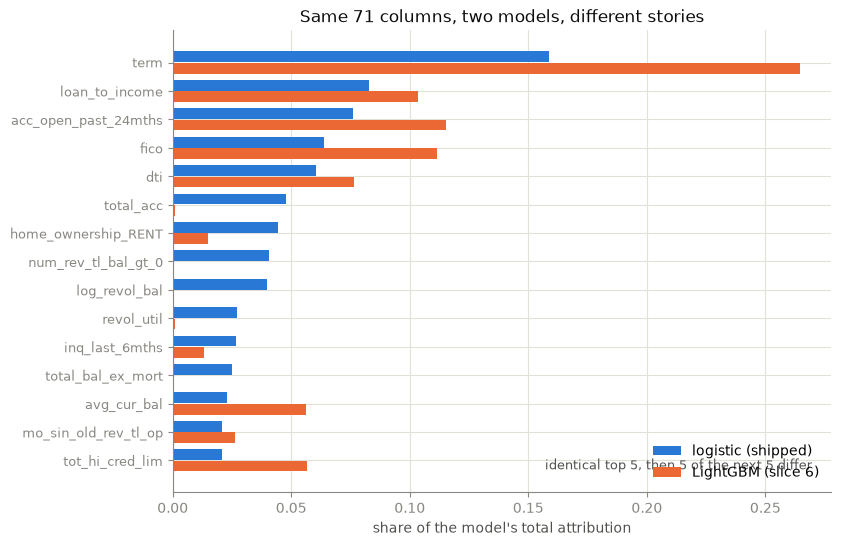

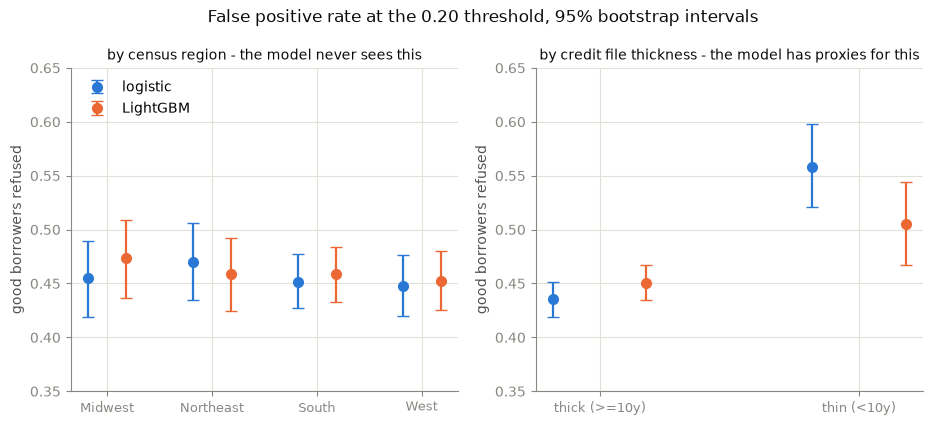

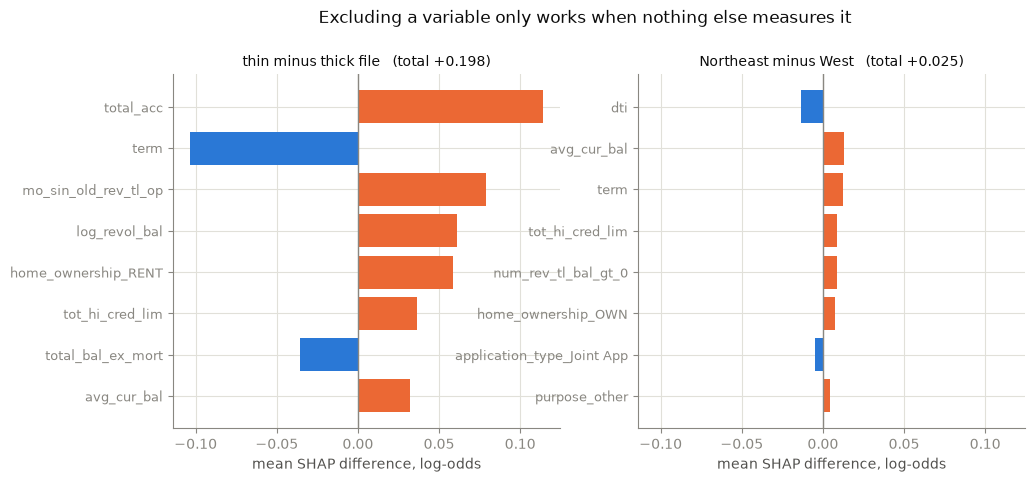

In [22]:
import matplotlib.pyplot as plt
from pathlib import Path

BLUE, ORANGE = "#2a78d6", "#eb6834"
GRID, MUTED, SOFT, INK, PAPER = "#e1e0d9", "#898781", "#52514e", "#0b0b0b", "#fcfcfb"

FIG_DIR = Path('../figures'); FIG_DIR.mkdir(exist_ok=True)


def style(ax):
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=MUTED)


# ============ A: the two models' importance, normalised ================
# each model's own scale differs, so compare SHARE of total attribution
share_log = imp['shap_logreg'] / imp['shap_logreg'].sum()
share_lgb = imp['shap_lgbm']   / imp['shap_lgbm'].sum()

top15 = share_log.nlargest(15).index[::-1]
ypos  = np.arange(len(top15))

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(ypos + 0.20, share_log[top15], height=0.38, color=BLUE,   label="logistic (shipped)")
ax.barh(ypos - 0.20, share_lgb[top15], height=0.38, color=ORANGE, label="LightGBM (slice 6)")

ax.set_yticks(ypos); ax.set_yticklabels(top15, fontsize=9)
ax.set_xlabel("share of the model's total attribution", color=SOFT)
ax.set_title("Same 71 columns, two models, different stories", color=INK)
ax.annotate("identical top 5, then 5 of the next 5 differ",
            xy=(0.97, 0.05), xycoords="axes fraction", ha="right",
            fontsize=9, color=SOFT)
style(ax); ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG_DIR / "slice07_importance.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()


# ============ B: who gets refused - FPR with intervals =================
def bars(df, metric):
    v  = df[metric].values.astype(float)
    return v, np.vstack([v - df[metric + '_lo'].values.astype(float),
                         df[metric + '_hi'].values.astype(float) - v])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

for ax, col, title in zip(axes, ['region', 'file'],
                          ["by census region - the model never sees this",
                           "by credit file thickness - the model has proxies for this"]):
    names = list(tables[col].index)
    x     = np.arange(len(names))

    for off, tab, c, lab in [(-0.18, tables,     BLUE,   "logistic"),
                             (+0.18, tables_lgb, ORANGE, "LightGBM")]:
        v, err = bars(tab[col], 'fpr')
        ax.errorbar(x + off, v, yerr=err, fmt='o', color=c, capsize=4,
                    markersize=7, linewidth=1.6, label=lab)

    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=9)
    ax.set_ylabel("good borrowers refused", color=SOFT)
    ax.set_title(title, color=INK, fontsize=10)
    ax.set_ylim(0.35, 0.65)
    style(ax)

axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("False positive rate at the 0.20 threshold, 95% bootstrap intervals",
             color=INK, y=1.02)
fig.savefig(FIG_DIR / "slice07_fairness_fpr.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()


# ============ C: what carries each gap - SAME SCALE =====================
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)

for ax, d, title in zip(
        axes, [d_file, d_region],
        [f"thin minus thick file   (total {d_file.sum():+.3f})",
         f"Northeast minus West   (total {d_region.sum():+.3f})"]):

    top = d.reindex(d.abs().sort_values(ascending=False).index).head(8)[::-1]
    ax.barh(np.arange(len(top)), top.values,
            color=[ORANGE if v > 0 else BLUE for v in top.values])
    ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(top.index, fontsize=9)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_xlabel("mean SHAP difference, log-odds", color=SOFT)
    ax.set_title(title, color=INK, fontsize=10)
    style(ax)

fig.suptitle("Excluding a variable only works when nothing else measures it",
             color=INK, y=1.02)
fig.savefig(FIG_DIR / "slice07_gap_decomposition.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()

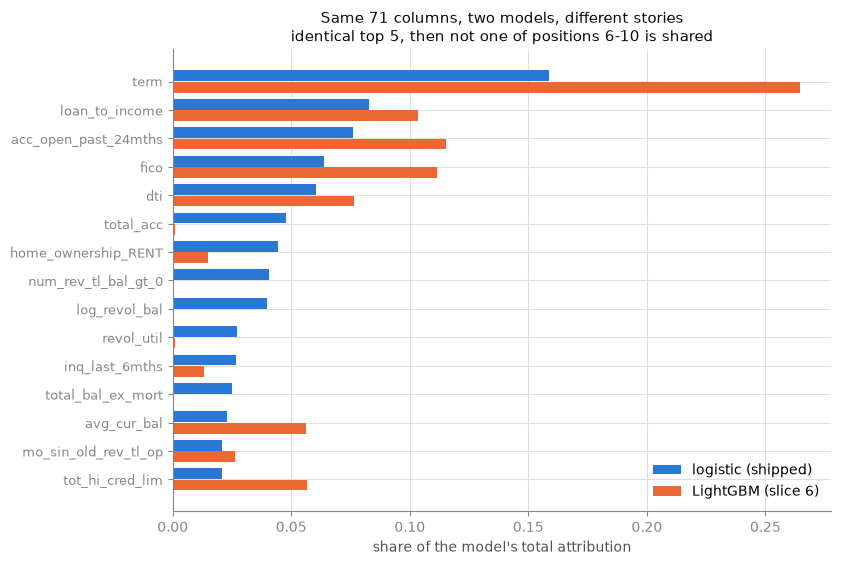

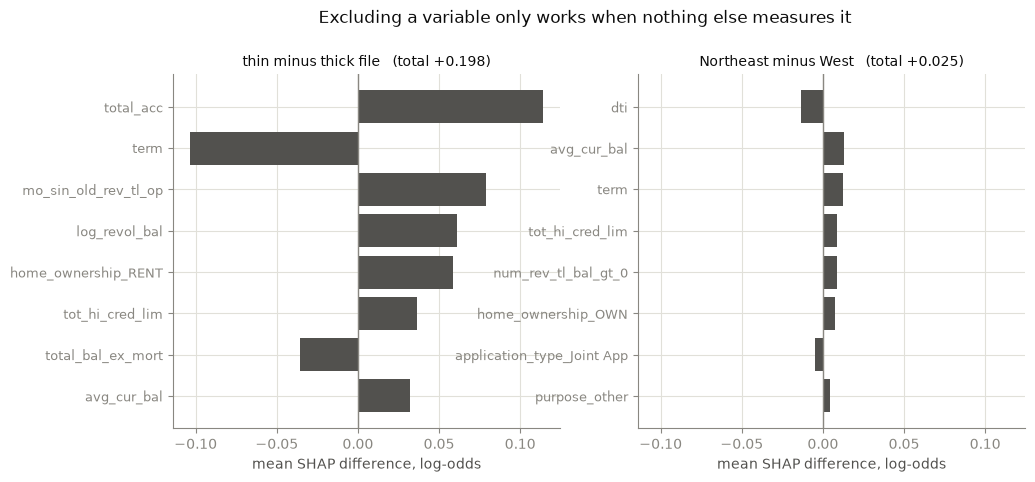

In [23]:
# ---- A, fixed: note moved into the title, no collision -----------------
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(ypos + 0.20, share_log[top15], height=0.38, color=BLUE,   label="logistic (shipped)")
ax.barh(ypos - 0.20, share_lgb[top15], height=0.38, color=ORANGE, label="LightGBM (slice 6)")

ax.set_yticks(ypos); ax.set_yticklabels(top15, fontsize=9)
ax.set_xlabel("share of the model's total attribution", color=SOFT)
ax.set_title("Same 71 columns, two models, different stories\n"
             "identical top 5, then not one of positions 6-10 is shared",
             color=INK, fontsize=11)
style(ax); ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG_DIR / "slice07_importance.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()


# ---- C, fixed: one colour, so blue/orange keeps meaning the two models --
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)

for ax, d, title in zip(
        axes, [d_file, d_region],
        [f"thin minus thick file   (total {d_file.sum():+.3f})",
         f"Northeast minus West   (total {d_region.sum():+.3f})"]):

    top = d.reindex(d.abs().sort_values(ascending=False).index).head(8)[::-1]
    ax.barh(np.arange(len(top)), top.values, color=SOFT)
    ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(top.index, fontsize=9)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_xlabel("mean SHAP difference, log-odds", color=SOFT)
    ax.set_title(title, color=INK, fontsize=10)
    style(ax)

fig.suptitle("Excluding a variable only works when nothing else measures it",
             color=INK, y=1.02)
fig.savefig(FIG_DIR / "slice07_gap_decomposition.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()